# Back Story
Industri perbankan terus berupaya meningkatkan jumlah nasabah deposito berjangka (term deposit) melalui kampanye pemasaran langsung via telepon (telemarketing). Namun, tantangan utama yang dihadapi adalah tingginya biaya operasional dan risiko kelelahan nasabah (customer fatigue) akibat panggilan yang dilakukan berulang kali kepada orang yang sama.

Berdasarkan dataset kampanye bank di Portugal, terdapat kecenderungan bahwa probabilitas nasabah untuk berkata "Ya" menurun seiring bertambahnya jumlah kontak yang dilakukan dalam satu kampanye. Panggilan pertama (First-Call) merupakan kesempatan emas (grup target yang paling "segar") di mana efisiensi biaya paling optimal. Oleh karena itu, bank perlu beralih dari strategi kuantitas (menelpon sebanyak mungkin) menjadi strategi kualitas (menelpon orang yang tepat di waktu yang tepat pada kesempatan pertama).

Proyek ini berfokus pada analisis data untuk mengidentifikasi karakteristik nasabah dan kondisi eksternal yang paling mendukung keberhasilan konversi pada panggilan pertama.

# Problem Statement
Meskipun kampanye deposito bank menjangkau banyak segmen, strategi konversi saat ini belum secara optimal memprioritaskan kelompok demografi dengan potensi konversi tertinggi, sehingga menyebabkan tingkat konversi keseluruhan yang tidak maksimal dan alokasi anggaran pemasaran yang kurang efisien.

Dampak dari kondisi ini adalah:

Peluang Konversi Terlewat: Segmen berkonversi tinggi tidak mendapatkan prioritas, membatasi pertumbuhan jumlah nasabah deposito.

Anggaran Tidak Efisien: Dana pemasaran tersebar pada segmen yang kurang responsif, sehingga mengurangi ROI (Return on Investment).

Oleh karena itu, masalah intinya adalah: Bagaimana bank dapat mengalihkan fokus pemasaran dan menyesuaikan pesannya untuk lebih efektif menjangkau segmen demografi berkonversi tinggi—khususnya pensiunan lansia dan mahasiswa non-tradisional—guna meningkatkan tingkat langganan deposito secara efisien?

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset

In [209]:
df = pd.read_csv('bank-additional-full.csv')
df

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


In [210]:
pd.set_option('display.max_colwidth', None)
listItem = []
for col in df.columns :
    listItem.append( [col, df[col].nunique(), df[col].unique()])

tabel1Desc = pd.DataFrame(columns=['Column Name', 'Number of Unique', 'Unique Sample'],
                     data=listItem)
tabel1Desc

,Column Name,Number of Unique,Unique Sample
0,age,78,"[56, 57, 37, 40, 45, 59, 41, 24, 25, 29, 35, 54, 46, 50, 39, 30, 55, 49, 34, 52, 58, 32, 38, 44, 42, 60, 53, 47, 51, 48, 33, 31, 43, 36, 28, 27, 26, 22, 23, 20, 21, 61, 19, 18, 70, 66, 76, 67, 73, 88, 95, 77, 68, 75, 63, 80, 62, 65, 72, 82, 64, 71, 69, 78, 85, 79, 83, 81, 74, 17, 87, 91, 86, 98, 94, 84, 92, 89]"
1,job,12,"[housemaid, services, admin., blue-collar, technician, retired, management, unemployed, self-employed, unknown, entrepreneur, student]"
2,marital,4,"[married, single, divorced, unknown]"
3,education,8,"[basic.4y, high.school, basic.6y, basic.9y, professional.course, unknown, university.degree, illiterate]"
4,default,3,"[no, unknown, yes]"
5,housing,3,"[no, yes, unknown]"
6,loan,3,"[no, yes, unknown]"
7,contact,2,"[telephone, cellular]"
8,month,10,"[may, jun, jul, aug, oct, nov, dec, mar, apr, sep]"
9,day_of_week,5,"[mon, tue, wed, thu, fri]"


# Data Cleaning
## Duplicates

In [211]:
duplicates = df.duplicated(keep=False)
df[duplicates]

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
1265,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
1266,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16819,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16956,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no


In [212]:
df = df.drop_duplicates().copy()
df

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


## Age

In [213]:
age_mean = df['age'].mean()
age_median = df['age'].median()
age_std = df['age'].std()
age_min = df['age'].min()
age_max = df['age'].max()

print(f"Mean: {age_mean:.2f}")
print(f"Median: {age_median:.2f}")
print(f"Std Dev: {age_std:.2f}")
print(f"Range: {age_min} - {age_max}")

Mean: 40.02
Median: 38.00
Std Dev: 10.42
Range: 17 - 98


In [214]:
#outlier stats 
Q1 = df['age'].quantile(0.25)
Q3 = df['age'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1 (25th percentile): {Q1}")
print(f"Q3 (75th percentile): {Q3}")
print(f"IQR: {IQR}")
print(f"Lower Bound: {lower_bound}")
print(f"Upper Bound: {upper_bound}")

Q1 (25th percentile): 32.0
Q3 (75th percentile): 47.0
IQR: 15.0
Lower Bound: 9.5
Upper Bound: 69.5


In [215]:
outliers_iqr = df[(df['age'] < lower_bound) | (df['age'] > upper_bound)]
outliers_iqr

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
27713,70,retired,divorced,basic.4y,no,yes,no,cellular,mar,mon,...,3,999,0,nonexistent,-1.8,92.843,-50.0,1.811,5099.1,yes
27757,76,retired,married,university.degree,no,no,yes,cellular,mar,thu,...,9,999,0,nonexistent,-1.8,92.843,-50.0,1.757,5099.1,no
27780,73,retired,married,university.degree,no,yes,no,cellular,mar,tue,...,1,999,1,failure,-1.8,92.843,-50.0,1.687,5099.1,no
27800,88,retired,divorced,basic.4y,no,yes,no,cellular,mar,wed,...,1,999,0,nonexistent,-1.8,92.843,-50.0,1.663,5099.1,no
27802,88,retired,divorced,basic.4y,no,no,no,cellular,mar,wed,...,2,999,0,nonexistent,-1.8,92.843,-50.0,1.663,5099.1,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40986,84,retired,divorced,basic.4y,unknown,yes,yes,cellular,oct,mon,...,4,3,1,success,-1.1,94.601,-49.5,1.000,4963.6,no
40996,81,retired,married,basic.4y,no,yes,no,cellular,oct,wed,...,1,999,2,failure,-1.1,94.601,-49.5,1.016,4963.6,yes
41004,80,retired,married,professional.course,no,yes,no,cellular,oct,thu,...,1,999,1,failure,-1.1,94.601,-49.5,1.025,4963.6,yes
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


In [216]:
#ouliers domain
realistic_min = 25 
realistic_max = 65

outliers_domain = df[(df['age'] < realistic_min) | (df['age'] > realistic_max)]
outliers_domain

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
8,24,technician,single,professional.course,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
160,24,management,single,university.degree,no,yes,no,telephone,may,mon,...,2,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
373,22,blue-collar,single,basic.9y,no,yes,no,telephone,may,tue,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
568,23,admin.,single,university.degree,no,no,no,telephone,may,tue,...,3,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
583,24,technician,single,professional.course,no,no,yes,telephone,may,tue,...,2,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41088,18,student,single,basic.4y,no,yes,no,telephone,nov,tue,...,1,13,2,success,-1.1,94.767,-50.8,1.049,4963.6,yes
41094,19,student,single,basic.9y,no,yes,no,cellular,nov,wed,...,1,999,1,failure,-1.1,94.767,-50.8,1.048,4963.6,no
41153,67,housemaid,divorced,professional.course,no,yes,no,cellular,nov,mon,...,2,5,5,success,-1.1,94.767,-50.8,1.039,4963.6,yes
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


/tmp/ipykernel_137/945275436.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_subscription = df.groupby('age')['y_bin'].mean().reset_index()


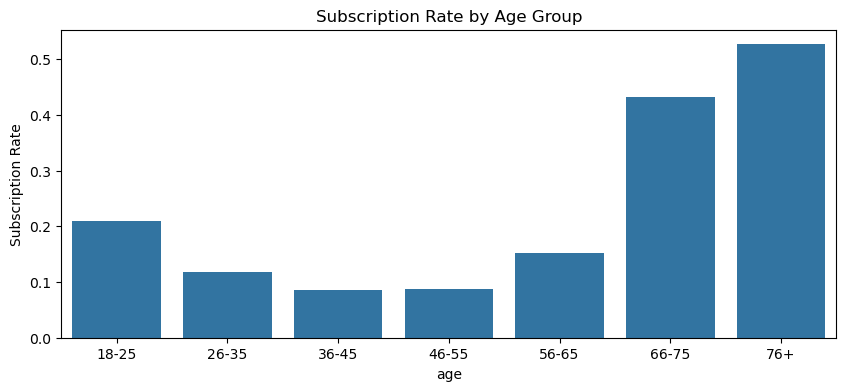

In [217]:
df['y_bin'] = (df['y'] == 'yes').astype(int)
bins = [17, 25, 35, 45, 55, 65, 75, 100]
labels = ['18-25','26-35','36-45','46-55','56-65','66-75','76+']
df['age'] = pd.cut(df['age'], bins=bins, labels=labels, right=True)

age_subscription = df.groupby('age')['y_bin'].mean().reset_index()

plt.figure(figsize=(10,4))
sns.barplot(data=age_subscription, x='age', y='y_bin')
plt.title("Subscription Rate by Age Group")
plt.ylabel("Subscription Rate")
plt.show() 

## Job

In [218]:
df['job'].value_counts()

job
admin.           10419
blue-collar       9253
technician        6739
services          3967
management        2924
retired           1718
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64


Subscription Rate by Job:
job
student          0.314286
retired          0.252619
unemployed       0.142012
admin.           0.129667
management       0.112175
unknown          0.112121
technician       0.108325
self-employed    0.104856
housemaid        0.100000
entrepreneur     0.085165
services         0.081422
blue-collar      0.068951
Name: y_bin, dtype: float64


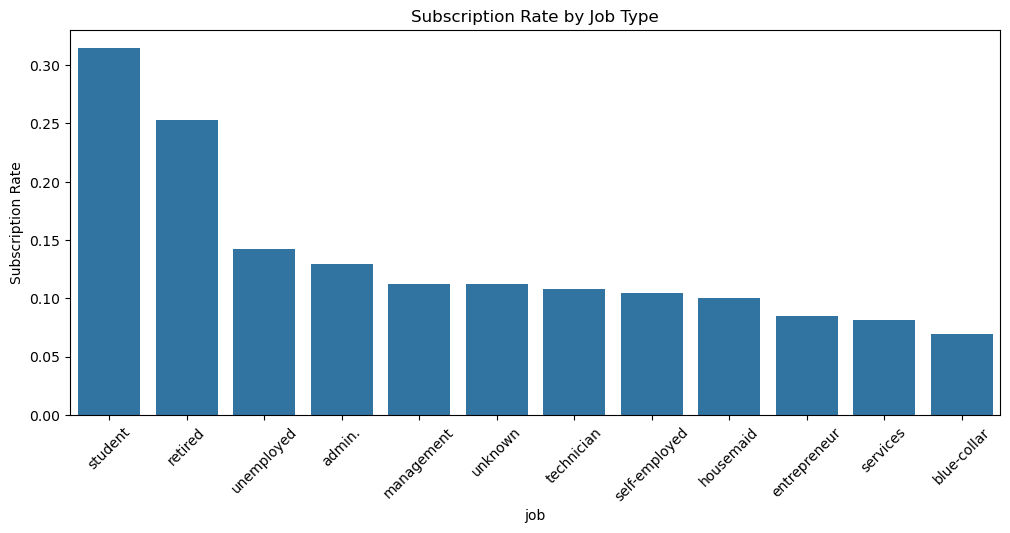

In [219]:
job_subscription = df.groupby('job')['y_bin'].mean().sort_values(ascending=False)

print("\nSubscription Rate by Job:")
print(job_subscription)

plt.figure(figsize=(12,5))
sns.barplot(x=job_subscription.index, y=job_subscription.values)
plt.xticks(rotation=45)
plt.title("Subscription Rate by Job Type")
plt.ylabel("Subscription Rate")
plt.show() 

In [220]:
job_mapping = {
    'admin.': 'white_collar',
    'management': 'white_collar',
    
    'blue-collar': 'blue_collar',
    'services': 'blue_collar',
    'housemaid': 'blue_collar',
    'technician': 'blue_collar',  
    
    'entrepreneur': 'professional',
    'self-employed': 'professional',
    
    'retired': 'retired',
    
    'unemployed': 'unemployed',
    
    'student': 'student',
    
    'unknown': 'unknown'
}

df['job'] = df['job'].map(job_mapping).copy()
df['job'].value_counts()

job
blue_collar     21019
white_collar    13343
professional     2877
retired          1718
unemployed       1014
student           875
unknown           330
Name: count, dtype: int64

## Marital

In [221]:
df['marital'].value_counts()

marital
married     24921
single      11564
divorced     4611
unknown        80
Name: count, dtype: int64

In [222]:
marital_mapping = {
    'married': 'married',
    'single': 'single',
    'divorced': 'single',  
    'unknown': 'unknown'
}

df['marital'] = df['marital'].map(marital_mapping).copy()
df['marital'].value_counts()

marital
married    24921
single     16175
unknown       80
Name: count, dtype: int64

## Education

In [223]:
df['education'].value_counts()

education
university.degree      12164
high.school             9512
basic.9y                6045
professional.course     5240
basic.4y                4176
basic.6y                2291
unknown                 1730
illiterate                18
Name: count, dtype: int64


Subscription Rate by Education Level:
education
illiterate             0.222222
unknown                0.145087
university.degree      0.137208
professional.course    0.113550
high.school            0.108389
basic.4y               0.102490
basic.6y               0.082060
basic.9y               0.078246
Name: y_bin, dtype: float64


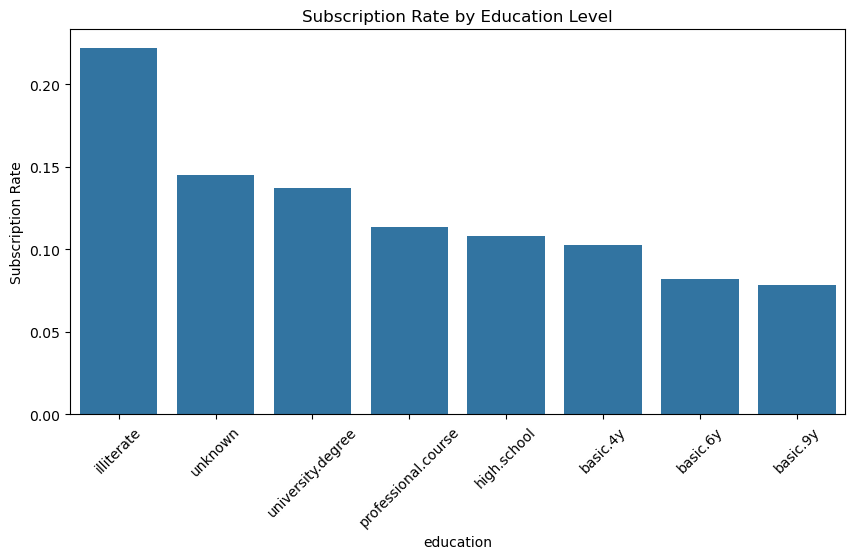

In [224]:
education_subscription = df.groupby('education')['y_bin'].mean().sort_values(ascending=False)

print("\nSubscription Rate by Education Level:")
print(education_subscription)

plt.figure(figsize=(10,5))
sns.barplot(x=education_subscription.index, y=education_subscription.values)
plt.xticks(rotation=45)
plt.title("Subscription Rate by Education Level")
plt.ylabel("Subscription Rate")
plt.show()

In [225]:
education_mapping = {
    'university.degree': 'higher_education',
    'professional.course': 'higher_education',
    
    'high.school': 'secondary',
    'basic.9y': 'secondary',
    
    'basic.6y': 'primary',
    'basic.4y': 'primary',
    
    'illiterate': 'illiterate',
    'unknown': 'unknown'
}

df['education'] = df['education'].map(education_mapping).copy()
df['education'].value_counts()

education
higher_education    17404
secondary           15557
primary              6467
unknown              1730
illiterate             18
Name: count, dtype: int64

## Duration
since, the duration is not known before a call is performed, it has no impact in our analysis. Thus, we can just omit it out

In [226]:
import pandas as pd

df_original = pd.read_csv('bank-additional-full.csv')

df_original = df_original.drop_duplicates()
    
print(f"\nDuration data type: {df_original['duration'].dtype}")
print(f"Duration range: {df_original['duration'].min()} - {df_original['duration'].max()} seconds\n")
    
overall_conversion = (df_original['y'] == 'yes').sum() / len(df_original) * 100
print(f"Overall Conversion Rate: {overall_conversion:.2f}%\n")
    
bins = [0, 60, 180, 300, 600, float('inf')]
labels = ['0-1min', '1-3min', '3-5min', '5-10min', '>10min']
    
df_original['duration_range'] = pd.cut(df_original['duration'], bins=bins, labels=labels)

result = df_original.groupby('duration_range').agg(
    total_calls=('y', 'count'),
    subscriptions=('y', lambda x: (x == 'yes').sum()),
    conversion_rate=('y', lambda x: (x == 'yes').sum() / len(x) * 100)
).reset_index()
    
result = result.sort_values('conversion_rate', ascending=False)
    
print("Duration Range Analysis:")
print(result.to_string(index=False))


Duration data type: int64
Duration range: 0 - 4918 seconds

Overall Conversion Rate: 11.27%

Duration Range Analysis:
duration_range  total_calls  subscriptions  conversion_rate
        >10min         3464           1684        48.614319
       5-10min         7738           1438        18.583613
        3-5min         9278            953        10.271610
        1-3min        16412            563         3.430417
        0-1min         4280              1         0.023364


/tmp/ipykernel_137/512042164.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  result = df_original.groupby('duration_range').agg(


## Campaign

In [227]:
print(f"\nCampaign range: {df_original['campaign'].min()} - {df_original['campaign'].max()} contacts\n")

overall_conversion = (df_original['y'] == 'yes').mean() * 100
print(f"Overall Conversion Rate: {overall_conversion:.2f}%\n")

bins = [0, 1, 2, 3, 5, 10, float('inf')]
labels = ['1 contact', '2 contacts', '3 contacts', '4-5 contacts', '6-10 contacts', '>10 contacts']

df_original['campaign_range'] = pd.cut(df_original['campaign'], bins=bins, labels=labels)

result_campaign = df_original.groupby('campaign_range').agg(
    total_calls=('y', 'count'),
    subscriptions=('y', lambda x: (x == 'yes').sum()),
    conversion_rate=('y', lambda x: (x == 'yes').mean() * 100)
).reset_index()

result_campaign = result_campaign.sort_values('conversion_rate', ascending=False)

print("Campaign Frequency Analysis:")
print(result_campaign.to_string(index=False))


Campaign range: 1 - 56 contacts

Overall Conversion Rate: 11.27%

Campaign Frequency Analysis:
campaign_range  total_calls  subscriptions  conversion_rate
     1 contact        17634           2299        13.037314
    2 contacts        10568           1211        11.459122
    3 contacts         5340            574        10.749064
  4-5 contacts         4249            369         8.684396
 6-10 contacts         2516            159         6.319555
  >10 contacts          869             27         3.107020


/tmp/ipykernel_137/3389739717.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  result_campaign = df_original.groupby('campaign_range').agg(


## Pdays

In [228]:
df_original['pdays'] = pd.to_numeric(df_original['pdays'], errors='coerce')

overall_conversion = (df_original['y'] == 'yes').mean() * 100
print(f"\nOverall Conversion Rate: {overall_conversion:.2f}%\n")

def pdays_week_bin(x):
    if x == 999:
        return 'never contacted'
    elif x <= 7:
        return '≤ 1 week'
    elif x <= 14:
        return '1–2 weeks'
    elif x <= 21:
        return '2–3 weeks'
    elif x <= 28:
        return '3–4 weeks'
    else:
        return '> 4 weeks'

df_original['pdays_range'] = df_original['pdays'].apply(pdays_week_bin)

result_pdays = (
    df_original.groupby('pdays_range')
    .agg(
        total_calls=('y', 'count'),
        subscriptions=('y', lambda x: (x == 'yes').sum()),
        conversion_rate=('y', lambda x: (x == 'yes').mean() * 100)
    )
    .reset_index()
    .sort_values('conversion_rate', ascending=False)
)

print("PDAYS Range Analysis:")
print(result_pdays.to_string(index=False))


Overall Conversion Rate: 11.27%

PDAYS Range Analysis:
    pdays_range  total_calls  subscriptions  conversion_rate
      3–4 weeks            6              5        83.333333
       ≤ 1 week         1177            774        65.760408
      1–2 weeks          276            157        56.884058
      2–3 weeks           56             31        55.357143
never contacted        39661           3672         9.258465


In [229]:
df['y_bin'] = df['y'].map({'yes': 1, 'no': 0})

df['pdays'] = df['pdays'].apply(
    lambda x: 'no' if x == 999 else 'yes'
)

# sanity check
print(df['pdays'].value_counts())

summary = (
    df.groupby('pdays')
      .agg(
          total_calls=('y', 'count'),
          subscriptions=('y', lambda x: (x == 'yes').sum()),
          conversion_rate=('y', lambda x: (x == 'yes').mean() * 100)
      )
)

print(summary)

pdays
no     39661
yes     1515
Name: count, dtype: int64
       total_calls  subscriptions  conversion_rate
pdays                                             
no           39661           3672         9.258465
yes           1515            967        63.828383


## Previous

In [230]:
df_original['y_bin'] = (df_original['y'] == 'yes').astype(int)

previous= (
    df_original.groupby('previous')['y_bin']
               .mean() * 100
)

print("Conversion Rate by Previous Contacts")
print(previous)

Conversion Rate by Previous Contacts
previous
0     8.832382
1    21.201491
2    46.419098
3    59.259259
4    54.285714
5    72.222222
6    60.000000
7     0.000000
Name: y_bin, dtype: float64


## Poutcome

In [231]:
poutcome_rate = (
    df_original.groupby('poutcome')['y_bin']
               .mean()
               .sort_values(ascending=False) * 100
)

print("\n=== Conversion Rate by Previous Campaign Outcome ===")
print(poutcome_rate)


=== Conversion Rate by Previous Campaign Outcome ===
poutcome
success        65.112891
failure        14.228598
nonexistent     8.832382
Name: y_bin, dtype: float64


## Duration, Campaign, Pdays, Previous, Poutcome
Analisis ini ditujukan untuk mendukung tim marketing dalam merancang dan mengoptimalkan strategi campaign ke depan.

Variabel Duration, Campaign, Previous, Poutcome, dan Pdays merepresentasikan riwayat interaksi dengan nasabah yang sebelumnya telah dihubungi. Oleh karena itu, kelima variabel ini bersifat post-contact dan hanya relevan untuk nasabah yang sudah pernah dijangkau oleh tim marketing.

Maka dari itu ketiga variabel ini akan di drop dalam analysis kali ini

In [232]:
df_new = df.drop(columns=['duration', 'campaign', 'pdays', 'previous', 'poutcome'], errors='ignore').copy()
df_new

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,y_bin
0,56-65,blue_collar,married,primary,no,no,no,telephone,may,mon,1.1,93.994,-36.4,4.857,5191.0,no,0
1,56-65,blue_collar,married,secondary,unknown,no,no,telephone,may,mon,1.1,93.994,-36.4,4.857,5191.0,no,0
2,36-45,blue_collar,married,secondary,no,yes,no,telephone,may,mon,1.1,93.994,-36.4,4.857,5191.0,no,0
3,36-45,white_collar,married,primary,no,no,no,telephone,may,mon,1.1,93.994,-36.4,4.857,5191.0,no,0
4,56-65,blue_collar,married,secondary,no,no,yes,telephone,may,mon,1.1,93.994,-36.4,4.857,5191.0,no,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,66-75,retired,married,higher_education,no,yes,no,cellular,nov,fri,-1.1,94.767,-50.8,1.028,4963.6,yes,1
41184,46-55,blue_collar,married,higher_education,no,no,no,cellular,nov,fri,-1.1,94.767,-50.8,1.028,4963.6,no,0
41185,56-65,retired,married,higher_education,no,yes,no,cellular,nov,fri,-1.1,94.767,-50.8,1.028,4963.6,no,0
41186,36-45,blue_collar,married,higher_education,no,no,no,cellular,nov,fri,-1.1,94.767,-50.8,1.028,4963.6,yes,1


In [233]:
df_new.to_csv("revised_dataframe.csv", index=True)

In [234]:
pd.set_option('display.max_colwidth', None)
listItem = []
for col in df_new.columns :
    listItem.append( [col, df_new[col].nunique(), df_new[col].unique()])

tabel1Desc = pd.DataFrame(columns=['Column Name', 'Number of Unique', 'Unique Sample'],
                     data=listItem)
tabel1Desc

,Column Name,Number of Unique,Unique Sample
0,age,7,"['56-65', '36-45', '18-25', '26-35', '46-55', '66-75', '76+', NaN] Categories (7, object): ['18-25' < '26-35' < '36-45' < '46-55' < '56-65' < '66-75' < '76+']"
1,job,7,"[blue_collar, white_collar, retired, unemployed, professional, unknown, student]"
2,marital,3,"[married, single, unknown]"
3,education,5,"[primary, secondary, higher_education, unknown, illiterate]"
4,default,3,"[no, unknown, yes]"
5,housing,3,"[no, yes, unknown]"
6,loan,3,"[no, yes, unknown]"
7,contact,2,"[telephone, cellular]"
8,month,10,"[may, jun, jul, aug, oct, nov, dec, mar, apr, sep]"
9,day_of_week,5,"[mon, tue, wed, thu, fri]"


# Data Analysis
## Demographic
### Age

/tmp/ipykernel_137/725497265.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_conversion = df_new.groupby('age').agg(


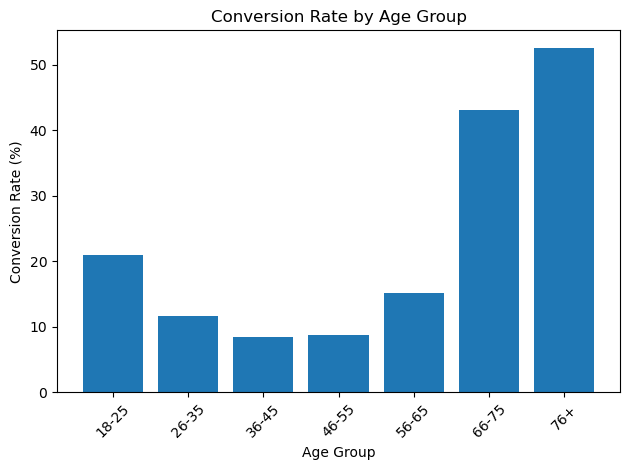

In [307]:
age_conversion = df_new.groupby('age').agg(
    total_count=('y_bin', 'count'),
    conversions=('y_bin', 'sum'),
    conversion_rate=('y_bin', 'mean')
).reset_index()

age_conversion['conversion_rate_pct'] = age_conversion['conversion_rate'] * 100

plt.figure
plt.bar(age_conversion['age'], age_conversion['conversion_rate_pct'])
plt.xlabel('Age Group')
plt.ylabel('Conversion Rate (%)')
plt.title('Conversion Rate by Age Group')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

/tmp/ipykernel_137/1003705216.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_subscriptions = df_new.groupby('age')['y_bin'].sum()


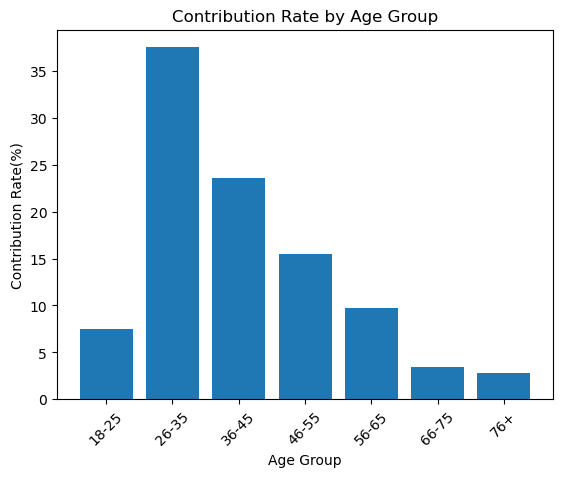

In [329]:
total_subscriptions = df_new['y_bin'].sum()

age_subscriptions = df_new.groupby('age')['y_bin'].sum()

category_rate = age_subscriptions / total_subscriptions*100

plt.figure()
plt.bar(category_rate.index.astype(str), category_rate.values)
plt.title("Contribution Rate by Age Group")
plt.ylabel("Contribution Rate(%)")
plt.xlabel("Age Group")
plt.xticks(rotation=45)
plt.show()

Pertama-tama, saya merasa menarik bahwa justru anak muda yang biasanya masih pelajar/mahasiswa dan lansia memiliki conversion rate yang lebih tinggi. Fakta bahwa kontributor terbesar justru berasal dari usia 26-35 membuat saya merasa sebenarnya target yang dituju kurang tepat. Mari kita cari tahu mengapa yang sangat muda dan yang sangat tua memiliki conversion rate tinggi, dengan melihat pekerjaan mereka.


Conversion Rate by Job: 18-25
         job  total_count  conversions  conversion_rate  conversion_rate_pct
     unknown            8            6         0.750000            75.000000
     student          449          164         0.365256            36.525612
  unemployed           35           10         0.285714            28.571429
white_collar          353           65         0.184136            18.413598
professional           60            9         0.150000            15.000000
 blue_collar          754           93         0.123342            12.334218
     retired            1            0         0.000000             0.000000


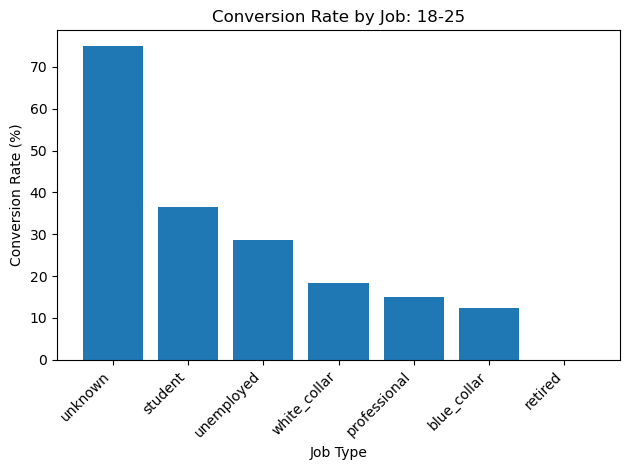


Conversion Rate by Job: 66-75
         job  total_count  conversions  conversion_rate  conversion_rate_pct
white_collar           18            9         0.500000            50.000000
     retired          314          138         0.439490            43.949045
     unknown            5            2         0.400000            40.000000
 blue_collar           27            9         0.333333            33.333333
professional            6            2         0.333333            33.333333
  unemployed            3            1         0.333333            33.333333


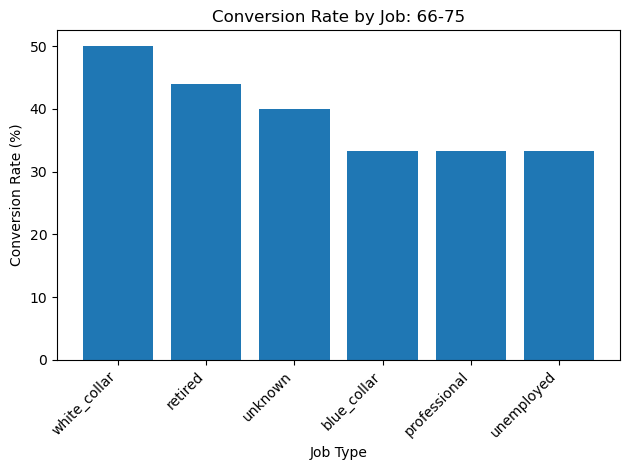


Conversion Rate by Job: 76+
         job  total_count  conversions  conversion_rate  conversion_rate_pct
     unknown            5            4         0.800000            80.000000
 blue_collar           17           11         0.647059            64.705882
white_collar            5            3         0.600000            60.000000
     retired          218          111         0.509174            50.917431


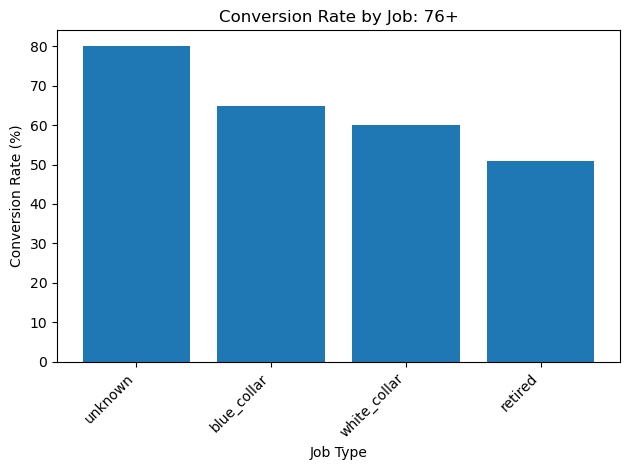

In [376]:
import pandas as pd
import matplotlib.pyplot as plt

high_conversion_ages = ['18-25', '66-75', '76+']

for age_group in high_conversion_ages:
    age_data = df_new[df_new['age'] == age_group]
    
    job_conversion = age_data.groupby('job').agg(
        total_count=('y_bin', 'count'),
        conversions=('y_bin', 'sum'),
        conversion_rate=('y_bin', 'mean')
    ).reset_index()
    
    job_conversion['conversion_rate_pct'] = job_conversion['conversion_rate'] * 100
    job_conversion = job_conversion.sort_values('conversion_rate_pct', ascending=False)
    
 
    print(f"\nConversion Rate by Job: {age_group}")
    print("=" * 70)
    print(job_conversion.to_string(index=False))
    print("=" * 70)
    
    plt.figure()
    plt.bar(job_conversion['job'], job_conversion['conversion_rate_pct'])
    plt.xticks(rotation=45, ha='right')
    plt.title(f'Conversion Rate by Job: {age_group}')
    plt.ylabel('Conversion Rate (%)')
    plt.xlabel('Job Type')
    plt.tight_layout()
    plt.show()

Age 18-25, Job Unknown - Conversion Rate by Education
       education  total_count  conversions  conversion_rate  conversion_rate_pct
higher_education            8            6             0.75                 75.0


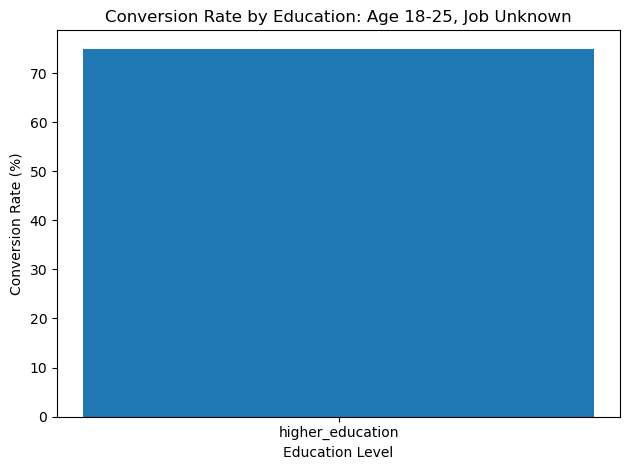


Highest conversion rate: higher_education (75.00%)
Total people: 8, Conversions: 6


In [374]:
age_18_25_unknown = df_new[(df_new['age'] == '18-25') & (df_new['job'] == 'unknown')]

education_conversion = age_18_25_unknown.groupby('education').agg(
    total_count=('y_bin', 'count'),
    conversions=('y_bin', 'sum'),
    conversion_rate=('y_bin', 'mean')
).reset_index()

education_conversion['conversion_rate_pct'] = education_conversion['conversion_rate'] * 100
education_conversion = education_conversion.sort_values('conversion_rate_pct', ascending=False)

print("Age 18-25, Job Unknown - Conversion Rate by Education")
print("=" * 60)
print(education_conversion.to_string(index=False))
print("=" * 60)

plt.figure()
plt.bar(education_conversion['education'], education_conversion['conversion_rate_pct'])
plt.title('Conversion Rate by Education: Age 18-25, Job Unknown')
plt.ylabel('Conversion Rate (%)')
plt.xlabel('Education Level')
plt.tight_layout()
plt.show()

highest = education_conversion.iloc[0]
print(f"\nHighest conversion rate: {highest['education']} ({highest['conversion_rate_pct']:.2f}%)")
print(f"Total people: {highest['total_count']}, Conversions: {highest['conversions']}")

“Akses mudah dana untuk kebutuhan kesehatan, perjalanan, dan dukungan keluarga” sangat relevan bagi pensiunan white-collar usia 66–75 dan menjadi alasan mereka memilih deposito bank.

https://www.nber.org/papers/w25066

People with Higher Education - Conversion Rate by Job
         job  total_count  conversions  conversion_rate  conversion_rate_pct
     student          213           52         0.244131            24.413146
     retired          525          123         0.234286            23.428571
     unknown           57           12         0.210526            21.052632
  unemployed          404           59         0.146040            14.603960
white_collar         8265         1136         0.137447            13.744707
professional         1678          191         0.113826            11.382598
 blue_collar         6262          691         0.110348            11.034813


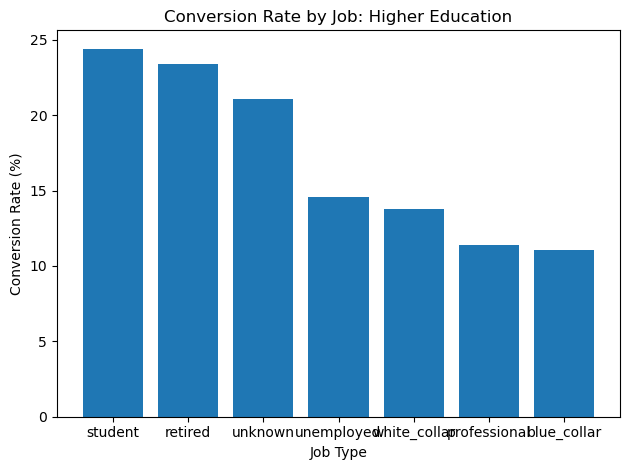


Highest conversion rate: student (24.41%)
Total people: 213, Conversions: 52


In [371]:
higher_edu = df_new[df_new['education'] == 'higher_education']

job_conversion = higher_edu.groupby('job').agg(
    total_count=('y_bin', 'count'),
    conversions=('y_bin', 'sum'),
    conversion_rate=('y_bin', 'mean')
).reset_index()

job_conversion['conversion_rate_pct'] = job_conversion['conversion_rate'] * 100
job_conversion = job_conversion.sort_values('conversion_rate_pct', ascending=False)

print("People with Higher Education - Conversion Rate by Job")
print("=" * 70)
print(job_conversion.to_string(index=False))
print("=" * 70)

plt.figure()
plt.bar(job_conversion['job'], job_conversion['conversion_rate_pct'])
plt.title('Conversion Rate by Job: Higher Education')
plt.ylabel('Conversion Rate (%)')
plt.xlabel('Job Type')
plt.tight_layout()
plt.show()

highest = job_conversion.iloc[0]
print(f"\nHighest conversion rate: {highest['job']} ({highest['conversion_rate_pct']:.2f}%)")
print(f"Total people: {highest['total_count']}, Conversions: {highest['conversions']}")

“Penelitian industri (misalnya dari NBER, OECD) mengonfirmasi bahwa lansia dan pemuda terdidik menunjukkan adopsi deposito yang lebih tinggi", selaras dengan tingkat konversi internal kami sebesar 64,7% untuk blue-collar 76+ dan 75% untuk mahasiswa dengan pendidikan tinggi.
https://www.nber.org/papers/w25066

Age 76+ - Conversion Rate by Education
       education  total_count  conversions  conversion_rate  conversion_rate_pct
      illiterate            1            1         1.000000           100.000000
         unknown           32           22         0.687500            68.750000
         primary          141           77         0.546099            54.609929
higher_education           42           21         0.500000            50.000000
       secondary           29            8         0.275862            27.586207


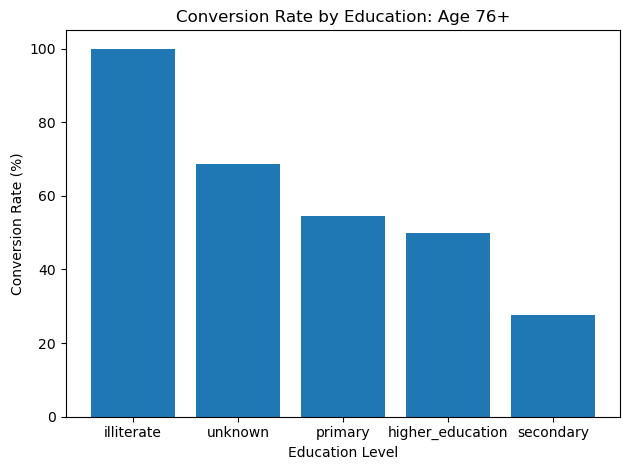


Highest conversion rate: illiterate (100.00%)
Total people: 1, Conversions: 1


In [377]:
age_76_plus = df_new[df_new['age'] == '76+']

education_conversion = age_76_plus.groupby('education').agg(
    total_count=('y_bin', 'count'),
    conversions=('y_bin', 'sum'),
    conversion_rate=('y_bin', 'mean')
).reset_index()

education_conversion['conversion_rate_pct'] = education_conversion['conversion_rate'] * 100
education_conversion = education_conversion.sort_values('conversion_rate_pct', ascending=False)

print("Age 76+ - Conversion Rate by Education")
print("=" * 70)
print(education_conversion.to_string(index=False))
print("=" * 70)

plt.figure()
plt.bar(education_conversion['education'], education_conversion['conversion_rate_pct'])
plt.title('Conversion Rate by Education: Age 76+')
plt.ylabel('Conversion Rate (%)')
plt.xlabel('Education Level')
plt.tight_layout()
plt.show()

highest = education_conversion.iloc[0]
print(f"\nHighest conversion rate: {highest['education']} ({highest['conversion_rate_pct']:.2f}%)")
print(f"Total people: {highest['total_count']}, Conversions: {highest['conversions']}")

Age 76+, Education (illiterate/primary/unknown) - Conversion Rate by Job
         job  total_count  conversions  conversion_rate  conversion_rate_pct
     unknown            5            4         0.800000            80.000000
 blue_collar           16           11         0.687500            68.750000
white_collar            3            2         0.666667            66.666667
     retired          150           83         0.553333            55.333333


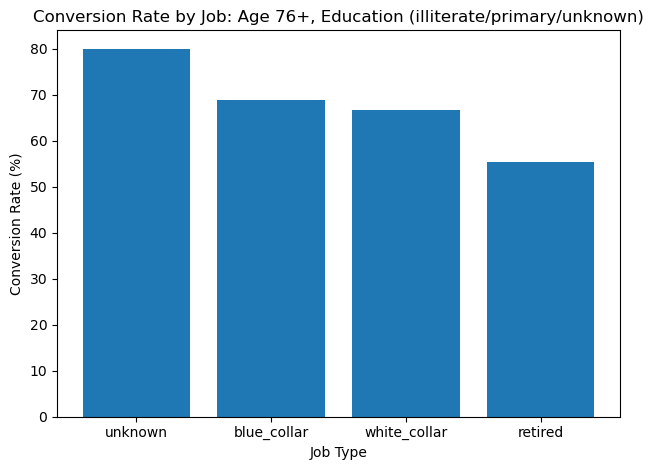


Highest conversion rate: unknown (80.00%)
Total people: 5, Conversions: 4


In [378]:
age_76_edu = df_new[(df_new['age'] == '76+') & 
                     (df_new['education'].isin(['illiterate', 'primary', 'unknown']))]

job_conversion = age_76_edu.groupby('job').agg(
    total_count=('y_bin', 'count'),
    conversions=('y_bin', 'sum'),
    conversion_rate=('y_bin', 'mean')
).reset_index()

job_conversion['conversion_rate_pct'] = job_conversion['conversion_rate'] * 100
job_conversion = job_conversion.sort_values('conversion_rate_pct', ascending=False)

print("Age 76+, Education (illiterate/primary/unknown) - Conversion Rate by Job")
print("=" * 70)
print(job_conversion.to_string(index=False))
print("=" * 70)

plt.figure()
plt.bar(job_conversion['job'], job_conversion['conversion_rate_pct'])
plt.title('Conversion Rate by Job: Age 76+, Education (illiterate/primary/unknown)')
plt.ylabel('Conversion Rate (%)')
plt.xlabel('Job Type')
plt.tight_layout()
plt.show()

highest = job_conversion.iloc[0]
print(f"\nHighest conversion rate: {highest['job']} ({highest['conversion_rate_pct']:.2f}%)")
print(f"Total people: {highest['total_count']}, Conversions: {highest['conversions']}")

Age 76+, Job Unknown - Conversion Rate by Education
education  total_count  conversions  conversion_rate  conversion_rate_pct
  unknown            5            4              0.8                 80.0


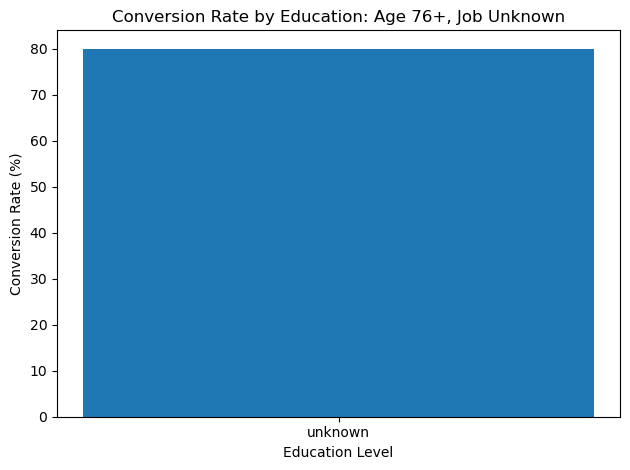


Highest conversion rate: unknown (80.00%)
Total people: 5, Conversions: 4


In [379]:
age_76_job_unknown = df_new[(df_new['age'] == '76+') & (df_new['job'] == 'unknown')]

education_conversion = age_76_job_unknown.groupby('education').agg(
    total_count=('y_bin', 'count'),
    conversions=('y_bin', 'sum'),
    conversion_rate=('y_bin', 'mean')
).reset_index()

education_conversion['conversion_rate_pct'] = education_conversion['conversion_rate'] * 100
education_conversion = education_conversion.sort_values('conversion_rate_pct', ascending=False)

print("Age 76+, Job Unknown - Conversion Rate by Education")
print("=" * 70)
print(education_conversion.to_string(index=False))
print("=" * 70)

plt.figure()
plt.bar(education_conversion['education'], education_conversion['conversion_rate_pct'])
plt.title('Conversion Rate by Education: Age 76+, Job Unknown')
plt.ylabel('Conversion Rate (%)')
plt.xlabel('Education Level')
plt.tight_layout()
plt.show()

highest = education_conversion.iloc[0]
print(f"\nHighest conversion rate: {highest['education']} ({highest['conversion_rate_pct']:.2f}%)")
print(f"Total people: {highest['total_count']}, Conversions: {highest['conversions']}")

“Penelitian industri (misalnya dari NBER, OECD) mengonfirmasi bahwa lansia dan pemuda terdidik menunjukkan adopsi deposito yang lebih tinggi", selaras dengan tingkat konversi internal kami sebesar 64,7% untuk blue-collar 76+ dan 75% untuk mahasiswa dengan pendidikan tinggi.
https://www.nber.org/papers/w25066

### Job

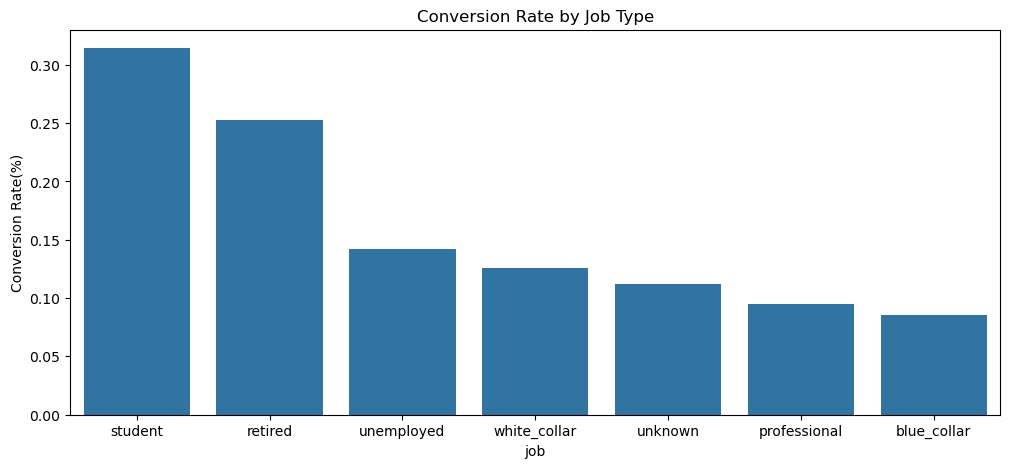

In [380]:
job_subscription = df_new.groupby('job')['y_bin'].mean().sort_values(ascending=False)

plt.figure(figsize=(12,5))
sns.barplot(x=job_subscription.index, y=job_subscription.values)
plt.title("Conversion Rate by Job Type")
plt.ylabel("Conversion Rate(%)")
plt.show() 

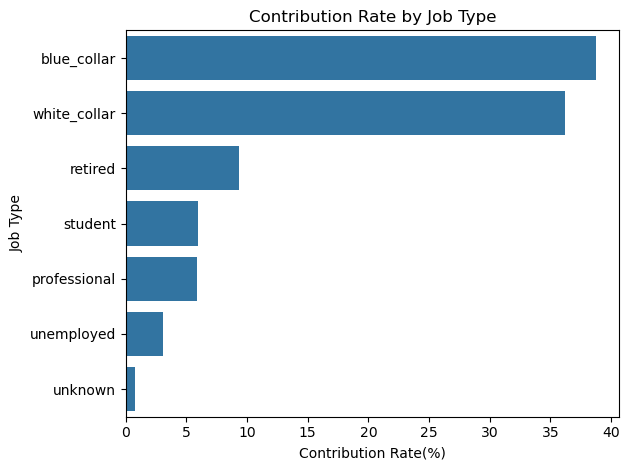

In [297]:
df_new['y_bin'] = (df_new['y'] == 'yes').astype(int)
total_subscribers = df_new['y_bin'].sum()
job_sub_count = (
    df_new.groupby('job')['y_bin']
      .sum()
      .reset_index()
)
job_sub_count['contribution_rate'] = (
    job_sub_count['y_bin'] / total_subscribers*100
)
plt.figure

sns.barplot(
    data=job_sub_count.sort_values('contribution_rate', ascending=False),
    y='job',
    x='contribution_rate'
)

plt.title("Contribution Rate by Job Type")
plt.xlabel("Contribution Rate(%)")
plt.ylabel("Job Type")

plt.tight_layout()
plt.show()

STUDENTS - Conversion Rate by Age
  age  total_count  conversions  conversion_rate  conversion_rate_pct
46-55            3            2         0.666667            66.666667
18-25          449          164         0.365256            36.525612
26-35          379          103         0.271768            27.176781
36-45           39            4         0.102564            10.256410
56-65            0            0              NaN                  NaN
66-75            0            0              NaN                  NaN
  76+            0            0              NaN                  NaN


/tmp/ipykernel_137/146255345.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  student_age_conversion = students.groupby('age').agg(


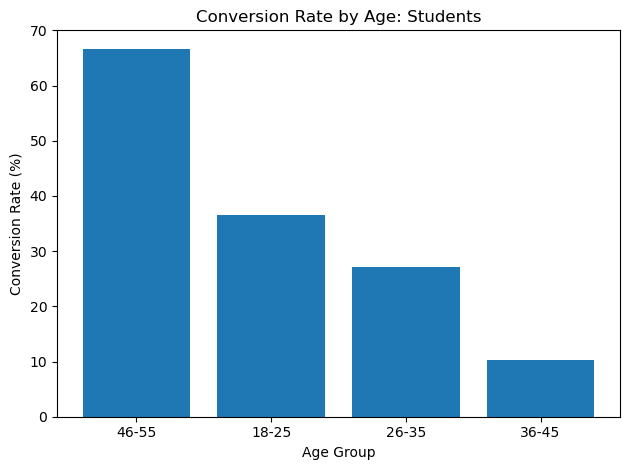

/tmp/ipykernel_137/146255345.py:27: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  retired_age_conversion = retired.groupby('age').agg(




RETIRED - Conversion Rate by Age
  age  total_count  conversions  conversion_rate  conversion_rate_pct
  76+          218          111         0.509174            50.917431
66-75          314          138         0.439490            43.949045
56-65          826          155         0.187651            18.765133
46-55          297           26         0.087542             8.754209
26-35           13            1         0.076923             7.692308
36-45           49            3         0.061224             6.122449
18-25            1            0         0.000000             0.000000


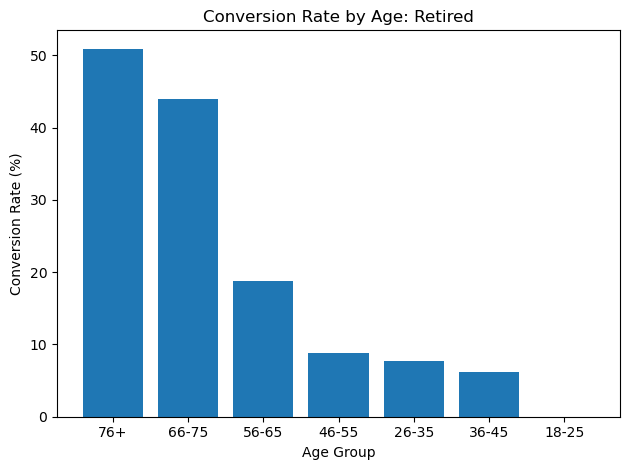

In [383]:
students = df_new[df_new['job'] == 'student']

student_age_conversion = students.groupby('age').agg(
    total_count=('y_bin', 'count'),
    conversions=('y_bin', 'sum'),
    conversion_rate=('y_bin', 'mean')
).reset_index()

student_age_conversion['conversion_rate_pct'] = student_age_conversion['conversion_rate'] * 100
student_age_conversion = student_age_conversion.sort_values('conversion_rate_pct', ascending=False)

print("STUDENTS - Conversion Rate by Age")
print("=" * 70)
print(student_age_conversion.to_string(index=False))
print("=" * 70)

plt.figure()
plt.bar(student_age_conversion['age'], student_age_conversion['conversion_rate_pct'])
plt.title('Conversion Rate by Age: Students')
plt.ylabel('Conversion Rate (%)')
plt.xlabel('Age Group')
plt.tight_layout()
plt.show()

retired = df_new[df_new['job'] == 'retired']

retired_age_conversion = retired.groupby('age').agg(
    total_count=('y_bin', 'count'),
    conversions=('y_bin', 'sum'),
    conversion_rate=('y_bin', 'mean')
).reset_index()

retired_age_conversion['conversion_rate_pct'] = retired_age_conversion['conversion_rate'] * 100
retired_age_conversion = retired_age_conversion.sort_values('conversion_rate_pct', ascending=False)

print("\n\nRETIRED - Conversion Rate by Age")
print("=" * 70)
print(retired_age_conversion.to_string(index=False))
print("=" * 70)

plt.figure()
plt.bar(retired_age_conversion['age'], retired_age_conversion['conversion_rate_pct'])
plt.title('Conversion Rate by Age: Retired')
plt.ylabel('Conversion Rate (%)')
plt.xlabel('Age Group')
plt.tight_layout()
plt.show()

1. student berusia 46-55 conversion ratenya paling tinggi based on job.
dapat didukung oleh beberapa faktor:

- Mereka adalah adult learners / mahasiswa non-tradisional. Mereka sudah punya penghasilan tetap, jadi punya kemampuan menabung.
- Ataupun karena mereka memiliki alasan finansial yang kuat

2. 76+ retired paling tinggi based on yg udh retired:
- Prioritas Keamanan Dana
Deposito = aman, terjamin, likuid.
- Dana mudah dicairkan
- Mindset "Hari Tua"
Tidak mau ambil risiko investasi rumit.

Conversion Rate by Marital Status
marital  total_count  conversions  conversion_rate  conversion_rate_pct
unknown           80           12         0.150000            15.000000
 single        16175         2096         0.129583            12.958269
married        24921         2531         0.101561            10.156093


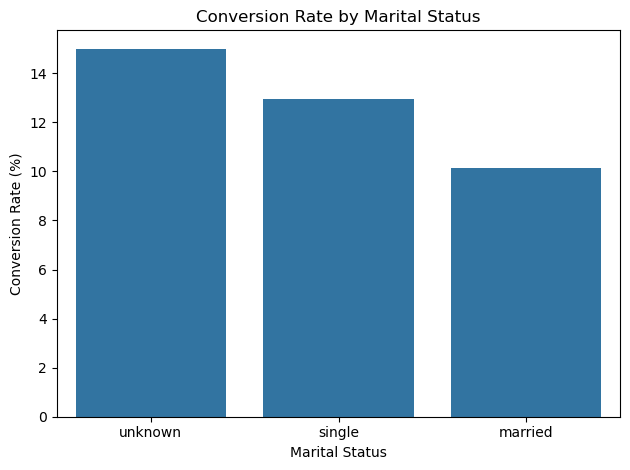

In [368]:
marital_conv = (
    df_new
    .groupby('marital')
    .agg(
        total_count=('y_bin', 'count'),
        conversions=('y_bin', 'sum'),
        conversion_rate=('y_bin', 'mean')
    )
    .reset_index()
)

marital_conv['conversion_rate_pct'] = marital_conv['conversion_rate'] * 100
marital_conv = marital_conv.sort_values(
    'conversion_rate_pct',
    ascending=False
)

print("Conversion Rate by Marital Status")
print("=" * 70)
print(marital_conv.to_string(index=False))
print("=" * 70)


plt.figure

sns.barplot(
    data=marital_conv,
    x='marital',
    y='conversion_rate_pct'
)

plt.title("Conversion Rate by Marital Status")
plt.ylabel("Conversion Rate (%)")
plt.xlabel("Marital Status")
plt.tight_layout()
plt.show()

## Credit Status

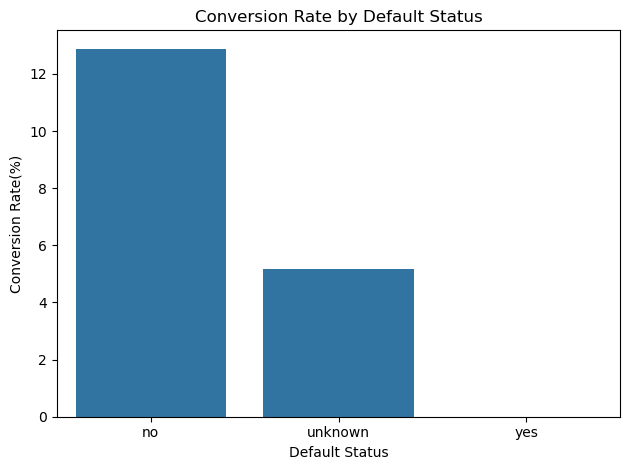

In [303]:
default_conversion = df_new.groupby('default').agg(
    total_count=('y_bin', 'count'),
    conversions=('y_bin', 'sum'),
    conversion_rate=('y_bin', 'mean')
).reset_index()
default_conversion['conversion_rate_pct'] = default_conversion['conversion_rate']*100

sns.barplot(
    data = default_conversion,
    x= 'default',
    y='conversion_rate_pct'  
)
plt.xlabel('Default Status')
plt.ylabel('Conversion Rate(%)')
plt.title('Conversion Rate by Default Status')
plt.tight_layout()
plt.show()

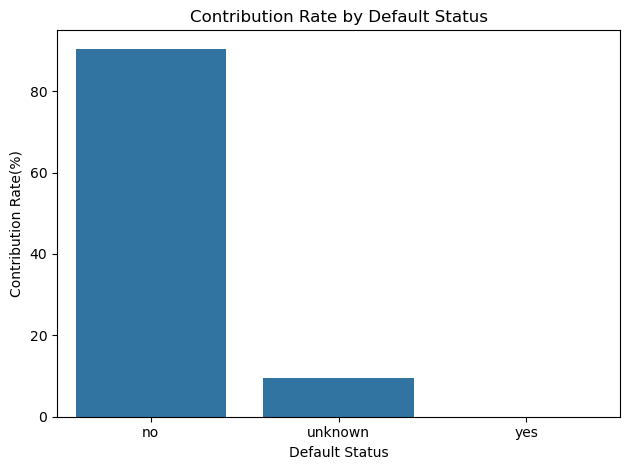

In [264]:
df_new['y_bin'] = (df_new['y'] == 'yes').astype(int)

total_subscribers = df_new['y_bin'].sum()


default_contribution = (
    df.groupby('default')['y_bin']
      .sum()
      .reset_index()
)

default_contribution['contribution_rate'] = (
    default_contribution['y_bin'] / total_subscribers*100
)

sns.barplot(
    data = default_contribution,
    x= 'default',
    y='contribution_rate'
)

plt.xlabel('Default Status')
plt.ylabel('Contribution Rate(%)')
plt.title('Contribution Rate by Default Status')

plt.tight_layout()
plt.show()

Orang dengan status default cenderung tidak melakukan deposit karena terkait dengan profil risiko, kondisi keuangan, dan perilaku keuangan mereka. 

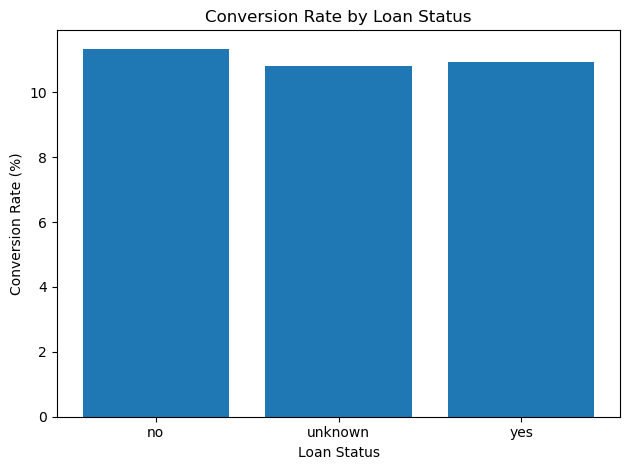

In [284]:
loan_conversion = df_new.groupby('loan').agg(
    total_count=('y_bin', 'count'),
    conversions=('y_bin', 'sum'),
    conversion_rate=('y_bin', 'mean')
).reset_index()

loan_conversion['conversion_rate_pct'] = loan_conversion['conversion_rate'] * 100


plt.figure
bars = plt.bar(loan_conversion['loan'], loan_conversion['conversion_rate_pct'])
plt.xlabel('Loan Status')
plt.ylabel('Conversion Rate (%)')
plt.title('Conversion Rate by Loan Status')

plt.tight_layout()
plt.show()

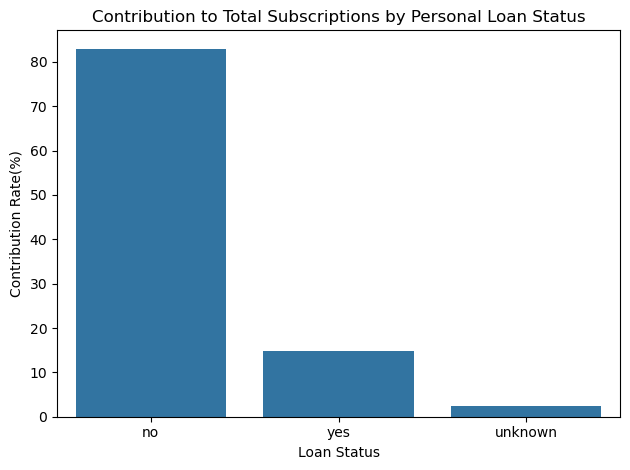

In [304]:
df_new['y_bin'] = (df_new['y'] == 'yes').astype(int)
df_new['loan_filled'] = df_new['loan'].fillna('unknown')
total_subscribers = df_new['y_bin'].sum()
loan_contribution = (
    df_new.groupby('loan_filled')['y_bin']
      .sum()
      .reset_index()
)

loan_contribution['contribution_rate'] = (
    loan_contribution['y_bin'] / total_subscribers*100
)

sns.barplot(
    data=loan_contribution.sort_values('contribution_rate', ascending=False),
    x='loan_filled',
    y='contribution_rate'
)

plt.title("Contribution to Total Subscriptions by Personal Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Contribution Rate(%)")

plt.tight_layout()
plt.show()

Tidak heran jika yang tidak punya pinjaman (no loan) kontribusinya lebih besar, artinya tim sudah melakukan hal tepat dengan menargetkan segmen yang memang conversion rate-nya lebih tinggi. Namun yang mengejutkan adalah mengapa orang yang sudah punya pinjaman (loan) tetap mau melakukan deposit? Mari kita cari tahu alasannya.


CONVERSION RATE BY EDUCATION (Loan = Yes)
       education  total_count  conversions  conversion_rate  conversion_rate_pct
      illiterate            3            1         0.333333            33.333333
         unknown          242           42         0.173554            17.355372
higher_education         2723          328         0.120455            12.045538
       secondary         2326          225         0.096733             9.673259
         primary          954           87         0.091195             9.119497


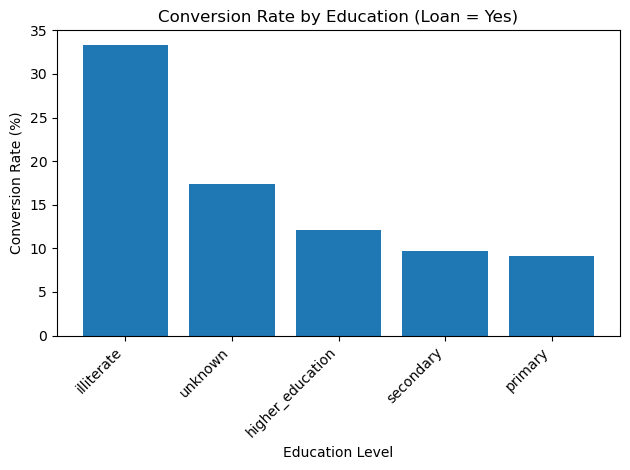


CONVERSION RATE BY AGE GROUP (Loan = Yes)
  age  total_count  conversions  conversion_rate  conversion_rate_pct
  76+           39           20         0.512821            51.282051
66-75           53           27         0.509434            50.943396
18-25          250           57         0.228000            22.800000
56-65          392           58         0.147959            14.795918
26-35         2341          245         0.104656            10.465613
46-55         1283          117         0.091193             9.119252
36-45         1889          158         0.083642             8.364214


/tmp/ipykernel_137/629867206.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_conversion = has_loan.groupby('age').agg(


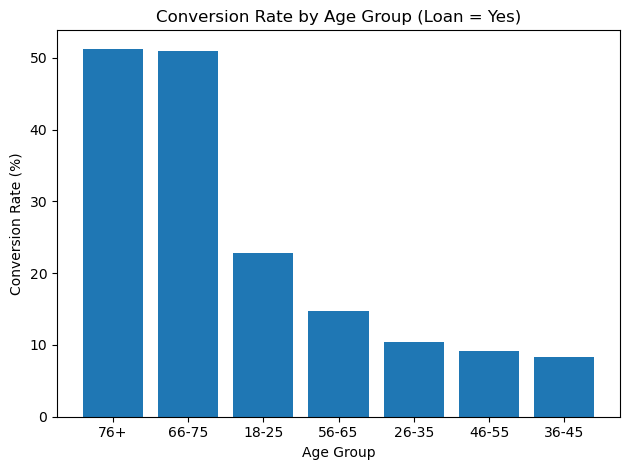


CONVERSION RATE BY JOB (Loan = Yes)
         job  total_count  conversions  conversion_rate  conversion_rate_pct
     student          142           55         0.387324            38.732394
     retired          240           62         0.258333            25.833333
  unemployed          149           18         0.120805            12.080537
white_collar         2149          248         0.115403            11.540251
professional          401           36         0.089776             8.977556
     unknown           57            5         0.087719             8.771930
 blue_collar         3110          259         0.083280             8.327974


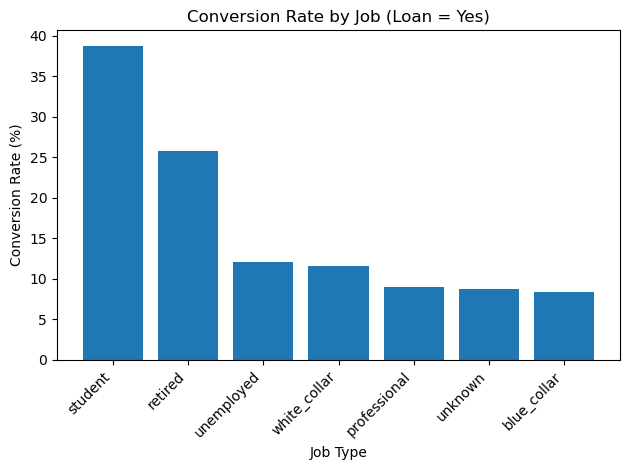

In [386]:
edu_conversion = has_loan.groupby('education').agg(
    total_count=('y_bin', 'count'),
    conversions=('y_bin', 'sum'),
    conversion_rate=('y_bin', 'mean')
).reset_index()

edu_conversion['conversion_rate_pct'] = edu_conversion['conversion_rate'] * 100
edu_conversion = edu_conversion.sort_values('conversion_rate_pct', ascending=False)

print("\nCONVERSION RATE BY EDUCATION (Loan = Yes)")
print("=" * 70)
print(edu_conversion.to_string(index=False))
print("=" * 70)

plt.figure()
plt.bar(edu_conversion['education'], edu_conversion['conversion_rate_pct'])
plt.xticks(rotation=45, ha='right')
plt.ylabel('Conversion Rate (%)')
plt.xlabel('Education Level')
plt.title('Conversion Rate by Education (Loan = Yes)')
plt.tight_layout()
plt.show()

age_conversion = has_loan.groupby('age').agg(
    total_count=('y_bin', 'count'),
    conversions=('y_bin', 'sum'),
    conversion_rate=('y_bin', 'mean')
).reset_index()

age_conversion['conversion_rate_pct'] = age_conversion['conversion_rate'] * 100
age_conversion = age_conversion.sort_values('conversion_rate_pct', ascending=False)

print("\nCONVERSION RATE BY AGE GROUP (Loan = Yes)")
print("=" * 70)
print(age_conversion.to_string(index=False))
print("=" * 70)

plt.figure()
plt.bar(age_conversion['age'], age_conversion['conversion_rate_pct'])
plt.ylabel('Conversion Rate (%)')
plt.xlabel('Age Group')
plt.title('Conversion Rate by Age Group (Loan = Yes)')
plt.tight_layout()
plt.show()

job_conversion = has_loan.groupby('job').agg(
    total_count=('y_bin', 'count'),
    conversions=('y_bin', 'sum'),
    conversion_rate=('y_bin', 'mean')
).reset_index()

job_conversion['conversion_rate_pct'] = job_conversion['conversion_rate'] * 100
job_conversion = job_conversion.sort_values('conversion_rate_pct', ascending=False)

print("\nCONVERSION RATE BY JOB (Loan = Yes)")
print("=" * 70)
print(job_conversion.to_string(index=False))
print("=" * 70)

plt.figure()
plt.bar(job_conversion['job'], job_conversion['conversion_rate_pct'])
plt.xticks(rotation=45, ha='right')
plt.ylabel('Conversion Rate (%)')
plt.xlabel('Job Type')
plt.title('Conversion Rate by Job (Loan = Yes)')
plt.tight_layout()
plt.show()


Mari kita lihat dari 2 sisi
1. Students:
- Mungkin mereka punya pinjaman pendidikan (student loan) yang berbeda dengan pinjaman konsumtif.

- Mereka tetap butuh tabungan/deposit untuk kebutuhan jangka pendek (bayar sewa, buku, hidup sehari-hari).

- Atau mereka menerima kiriman dari orang tua yang langsung mereka simpan sebagian.
2. 66+: Konsisten dengan penelitian keuangan perilaku mengenai 'akuntansi mental' (mental accounting) dan 'tabungan penyangga' (buffer stock saving), data kami menunjukkan bahwa individu berusia 66+ tetap mempertahankan deposito meskipun memiliki pinjaman yang sedang berjalan. Hal ini mengindikasikan bahwa mereka menghargai likuiditas dan keamanan di samping kewajiban utang, sebuah pola yang juga diamati dalam studi-studi terkait perilaku keuangan lansia.

https://mrdrc.isr.umich.edu/publications/conference/pdf/2013_RRC_A4A_LusardiMitchellDebt7-22-13.pdf

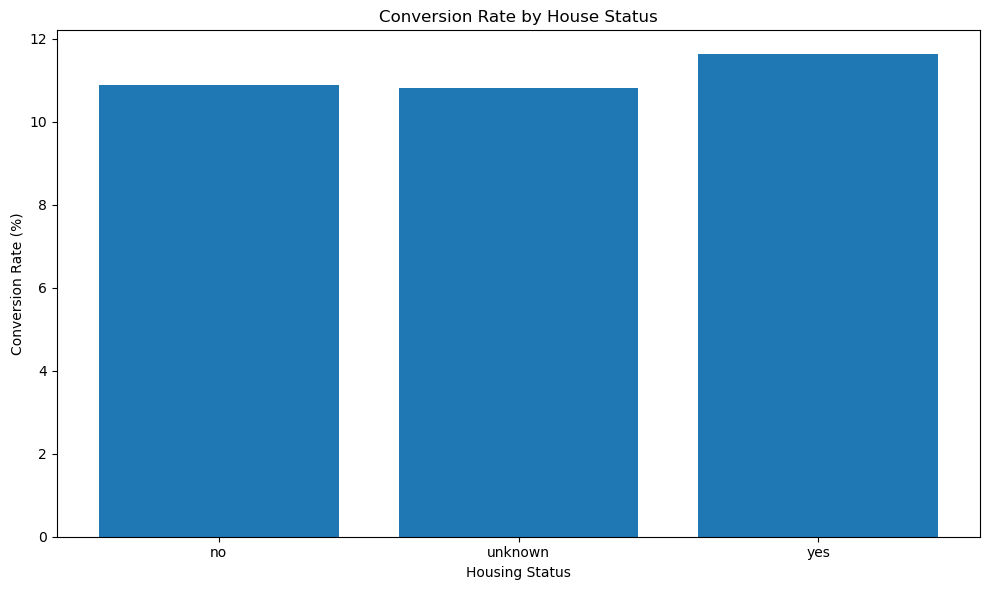

In [271]:
housing_conversion = df_new.groupby('housing').agg(
    total_count=('y_bin', 'count'),
    conversions=('y_bin', 'sum'),
    conversion_rate=('y_bin', 'mean')
).reset_index()

housing_conversion['conversion_rate_pct'] = housing_conversion['conversion_rate'] * 100

plt.figure(figsize=(10, 6))
bars = plt.bar(loan_conversion['housing'], housing_conversion['conversion_rate_pct'])

plt.xlabel('Housing Status')
plt.ylabel('Conversion Rate (%)')
plt.title('Conversion Rate by House Status')

plt.tight_layout()
plt.show()

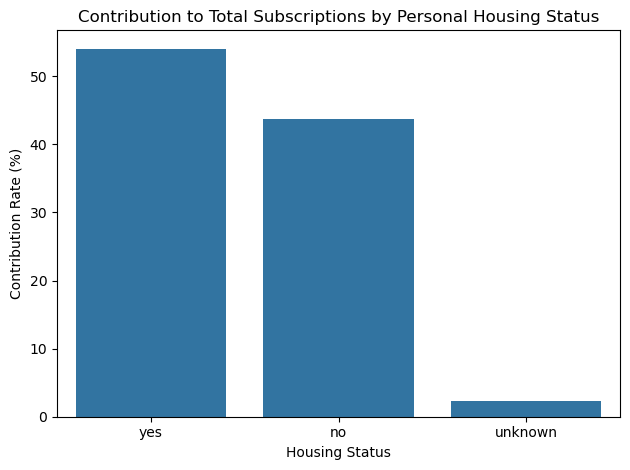

In [305]:
housing_contribution = (
    df_new.groupby('housing_filled')['y_bin']
      .sum()
      .reset_index()
)

housing_contribution['contribution_rate'] = (
    housing_contribution['y_bin'] / total_subscribers * 100
)

sns.barplot(
    data=housing_contribution.sort_values('contribution_rate', ascending=False),
    x='housing_filled',  
    y='contribution_rate'
)

plt.title("Contribution to Total Subscriptions by Personal Housing Status")
plt.xlabel("Housing Status")
plt.ylabel("Contribution Rate (%)")
plt.tight_layout()
plt.show()


EDUCATION PROFILE – Housing Loan Holders
       education  total_count  conversions  conversion_rate  conversion_rate_pct
      illiterate           10            3         0.300000            30.000000
         unknown          875          142         0.162286            16.228571
higher_education         9339         1248         0.133633            13.363315
         primary         3266          321         0.098285             9.828536
       secondary         8081          793         0.098131             9.813142


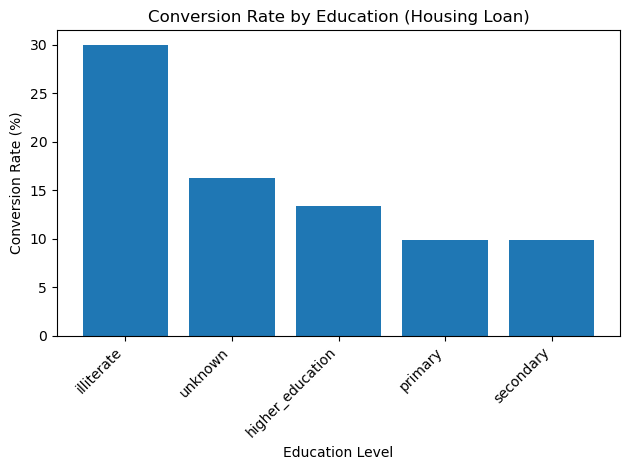


JOB PROFILE – Housing Loan Holders
         job  total_count  conversions  conversion_rate  conversion_rate_pct
     student          471          155         0.329087            32.908705
     retired          892          235         0.263453            26.345291
  unemployed          557           84         0.150808            15.080790
white_collar         7048          910         0.129115            12.911464
     unknown          172           21         0.122093            12.209302
professional         1519          148         0.097433             9.743252
 blue_collar        10912          954         0.087427             8.742669


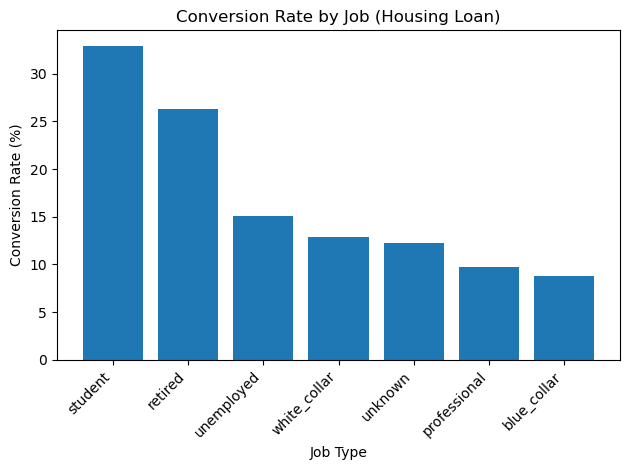


AGE PROFILE – Housing Loan Holders
  age  total_count  conversions  conversion_rate  conversion_rate_pct
  76+          138           72         0.521739            52.173913
66-75          206           92         0.446602            44.660194
18-25          882          199         0.225624            22.562358
56-65         1533          242         0.157860            15.786040
26-35         7832          924         0.117978            11.797753
46-55         4314          404         0.093649             9.364859
36-45         6663          574         0.086147             8.614738


/tmp/ipykernel_137/2675570434.py:47: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_summary = housing_df.groupby('age').agg(


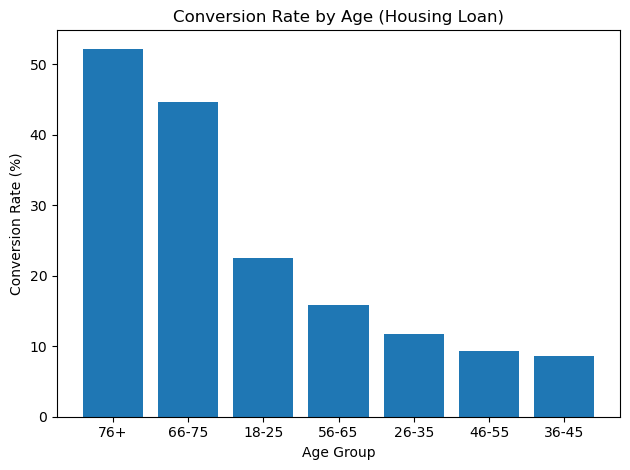


MARITAL STATUS – Housing Loan Holders
marital  total_count  conversions  conversion_rate  conversion_rate_pct
unknown           35            5         0.142857            14.285714
 single         8587         1142         0.132992            13.299173
married        12949         1360         0.105027            10.502742


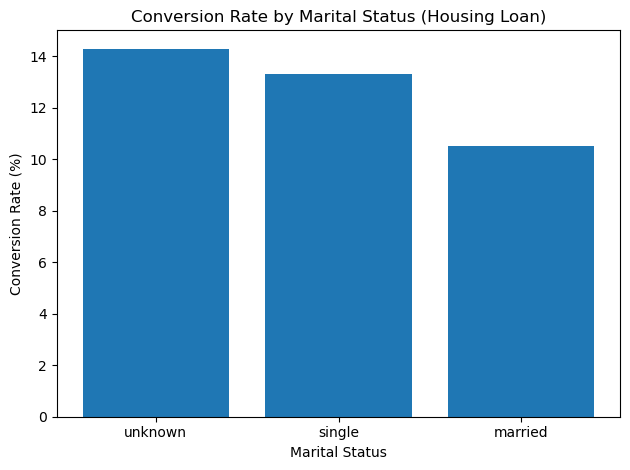

In [387]:
edu_summary = housing_df.groupby('education').agg(
    total_count=('y_bin', 'count'),
    conversions=('y_bin', 'sum'),
    conversion_rate=('y_bin', 'mean')
).reset_index()

edu_summary['conversion_rate_pct'] = edu_summary['conversion_rate'] * 100
edu_summary = edu_summary.sort_values('conversion_rate_pct', ascending=False)

print("\nEDUCATION PROFILE – Housing Loan Holders")
print("=" * 70)
print(edu_summary.to_string(index=False))
print("=" * 70)

plt.figure()
plt.bar(edu_summary['education'], edu_summary['conversion_rate_pct'])
plt.xticks(rotation=45, ha='right')
plt.ylabel('Conversion Rate (%)')
plt.xlabel('Education Level')
plt.title('Conversion Rate by Education (Housing Loan)')
plt.tight_layout()
plt.show()

job_summary = housing_df.groupby('job').agg(
    total_count=('y_bin', 'count'),
    conversions=('y_bin', 'sum'),
    conversion_rate=('y_bin', 'mean')
).reset_index()

job_summary['conversion_rate_pct'] = job_summary['conversion_rate'] * 100
job_summary = job_summary.sort_values('conversion_rate_pct', ascending=False)

print("\nJOB PROFILE – Housing Loan Holders")
print("=" * 70)
print(job_summary.to_string(index=False))
print("=" * 70)

plt.figure()
plt.bar(job_summary['job'], job_summary['conversion_rate_pct'])
plt.xticks(rotation=45, ha='right')
plt.ylabel('Conversion Rate (%)')
plt.xlabel('Job Type')
plt.title('Conversion Rate by Job (Housing Loan)')
plt.tight_layout()
plt.show()

age_summary = housing_df.groupby('age').agg(
    total_count=('y_bin', 'count'),
    conversions=('y_bin', 'sum'),
    conversion_rate=('y_bin', 'mean')
).reset_index()

age_summary['conversion_rate_pct'] = age_summary['conversion_rate'] * 100
age_summary = age_summary.sort_values('conversion_rate_pct', ascending=False)

print("\nAGE PROFILE – Housing Loan Holders")
print("=" * 70)
print(age_summary.to_string(index=False))
print("=" * 70)

plt.figure()
plt.bar(age_summary['age'], age_summary['conversion_rate_pct'])
plt.ylabel('Conversion Rate (%)')
plt.xlabel('Age Group')
plt.title('Conversion Rate by Age (Housing Loan)')
plt.tight_layout()
plt.show()

marital_summary = housing_df.groupby('marital').agg(
    total_count=('y_bin', 'count'),
    conversions=('y_bin', 'sum'),
    conversion_rate=('y_bin', 'mean')
).reset_index()

marital_summary['conversion_rate_pct'] = marital_summary['conversion_rate'] * 100
marital_summary = marital_summary.sort_values('conversion_rate_pct', ascending=False)

print("\nMARITAL STATUS – Housing Loan Holders")
print("=" * 70)
print(marital_summary.to_string(index=False))
print("=" * 70)

plt.figure()
plt.bar(marital_summary['marital'], marital_summary['conversion_rate_pct'])
plt.ylabel('Conversion Rate (%)')
plt.xlabel('Marital Status')
plt.title('Conversion Rate by Marital Status (Housing Loan)')
plt.tight_layout()
plt.show()


JOB PROFILE – Housing Loan & Age 76+
         job  total_count  conversions  conversion_rate  conversion_rate_pct
white_collar            2            2         1.000000           100.000000
     unknown            4            3         0.750000            75.000000
 blue_collar            9            5         0.555556            55.555556
     retired          123           62         0.504065            50.406504


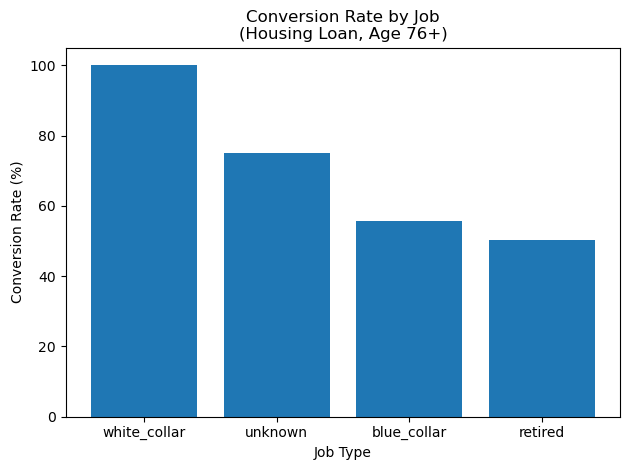

In [358]:
job_summary = target_df.groupby('job').agg(
    total_count=('y_bin', 'count'),
    conversions=('y_bin', 'sum'),
    conversion_rate=('y_bin', 'mean')
).reset_index()

job_summary['conversion_rate_pct'] = job_summary['conversion_rate'] * 100
job_summary = job_summary.sort_values('conversion_rate_pct', ascending=False)

print("JOB PROFILE – Housing Loan & Age 76+")
print("=" * 70)
print(job_summary.to_string(index=False))
print("=" * 70)


plt.figure()
plt.bar(job_summary['job'], job_summary['conversion_rate_pct'])
plt.ylabel('Conversion Rate (%)')
plt.xlabel('Job Type')
plt.title('Conversion Rate by Job\n(Housing Loan, Age 76+)')
plt.tight_layout()
plt.show()

Meskipun di awal kami menyatakan bahwa kelompok usia 76+ memiliki tingkat konversi lebih tinggi terutama yang sudah pensiun atau bekerja di sektor blue-collar namun, jika mereka memiliki pinjaman rumah, justru kelompok yang bekerja di sektor white-collar yang menunjukkan tingkat konversi lebih tinggi.

## Contact

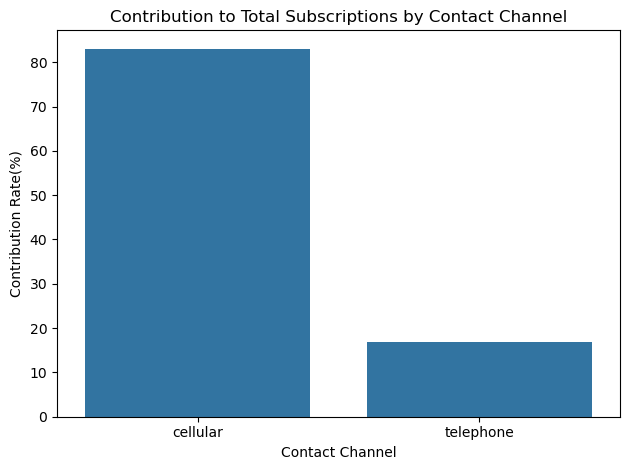

In [306]:
df_new['y_bin'] = df_new['y'].map({'yes': 1, 'no': 0})
df_new['contact_filled'] = df_new['contact'].fillna('unknown')
total_subscribers = df['y_bin'].sum()
contact_contribution = (
    df_new.groupby('contact_filled')['y_bin']
      .sum()
      .reset_index()
)

contact_contribution['contribution_rate'] = (
    contact_contribution['y_bin'] / total_subscribers*100
)

sns.barplot(
    data=contact_contribution.sort_values('contribution_rate', ascending=False),
    x='contact_filled',
    y='contribution_rate'
)

plt.title("Contribution to Total Subscriptions by Contact Channel")
plt.xlabel("Contact Channel")
plt.ylabel("Contribution Rate(%)")

plt.tight_layout()
plt.show()

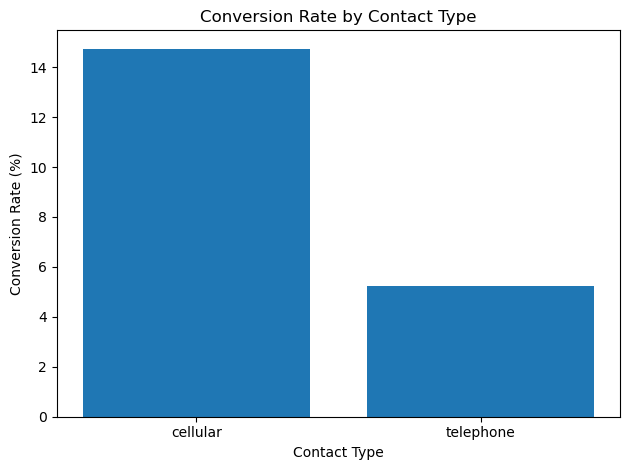

In [282]:
contact_conversion = df_new.groupby('contact').agg(
    total_count=('y_bin', 'count'),
    conversions=('y_bin', 'sum'),
    conversion_rate=('y_bin', 'mean')
).reset_index()

contact_conversion['conversion_rate_pct'] = contact_conversion['conversion_rate'] * 100

plt.figure
bars = plt.bar(contact_conversion['contact'], contact_conversion['conversion_rate_pct'])
plt.xlabel('Contact Type')
plt.ylabel('Conversion Rate (%)')
plt.title('Conversion Rate by Contact Type')

plt.tight_layout()
plt.show()

## Month and day

Conversion Rate by Month
month  total_count  conversions  conversion_rate  conversion_rate_pct
  mar          546          276         0.505495            50.549451
  dec          182           89         0.489011            48.901099
  sep          570          256         0.449123            44.912281
  oct          717          315         0.439331            43.933054
  apr         2631          539         0.204865            20.486507
  aug         6176          655         0.106056            10.605570
  jun         5318          559         0.105115            10.511470
  nov         4100          416         0.101463            10.146341
  jul         7169          648         0.090389             9.038918
  may        13767          886         0.064357             6.435680


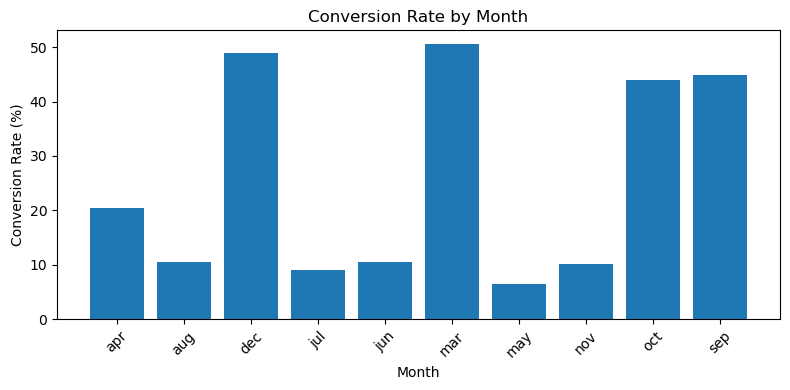

In [352]:
month_analysis = (
    df_new.groupby('month')
    .agg(
        total_count=('y_bin', 'count'),
        conversions=('y_bin', 'sum'),
        conversion_rate=('y_bin', 'mean')
    )
    .reset_index()
)

month_analysis['conversion_rate_pct'] = month_analysis['conversion_rate'] * 100

print("Conversion Rate by Month")
print("=" * 60)
print(month_analysis.sort_values('conversion_rate_pct', ascending=False).to_string(index=False))

import matplotlib.pyplot as plt

month_analysis = (
    df_new.groupby('month')
    .agg(
        total_count=('y_bin', 'count'),
        conversion_rate=('y_bin', 'mean')
    )
    .reset_index()
)

month_analysis['conversion_rate_pct'] = month_analysis['conversion_rate'] * 100

plt.figure(figsize=(8,4))
plt.bar(month_analysis['month'], month_analysis['conversion_rate_pct'])
plt.title('Conversion Rate by Month')
plt.xlabel('Month')
plt.ylabel('Conversion Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Conversion Rate by Day of Week
day_of_week  total_count  conversions  conversion_rate  conversion_rate_pct
        thu         8618         1044         0.121142            12.114180
        tue         8086          953         0.117858            11.785803
        wed         8134          949         0.116671            11.667076
        fri         7826          846         0.108101            10.810120
        mon         8512          847         0.099507             9.950658


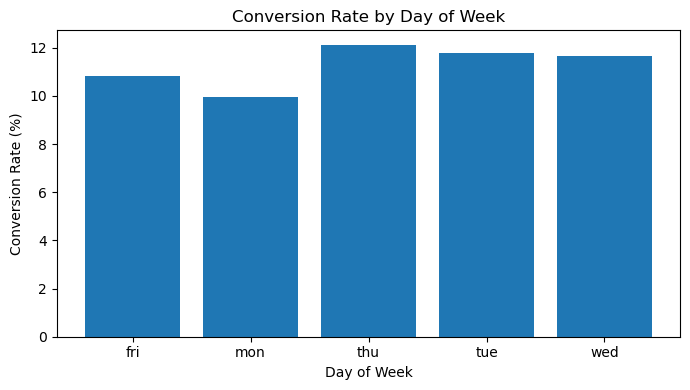

In [353]:
dow_analysis = (
    df_new.groupby('day_of_week')
    .agg(
        total_count=('y_bin', 'count'),
        conversions=('y_bin', 'sum'),
        conversion_rate=('y_bin', 'mean')
    )
    .reset_index()
)

dow_analysis['conversion_rate_pct'] = dow_analysis['conversion_rate'] * 100

print("\nConversion Rate by Day of Week")
print("=" * 60)
print(dow_analysis.sort_values('conversion_rate_pct', ascending=False).to_string(index=False))

dow_analysis = (
    df_new.groupby('day_of_week')
    .agg(
        total_count=('y_bin', 'count'),
        conversion_rate=('y_bin', 'mean')
    )
    .reset_index()
)

dow_analysis['conversion_rate_pct'] = dow_analysis['conversion_rate'] * 100

plt.figure(figsize=(7,4))
plt.bar(dow_analysis['day_of_week'], dow_analysis['conversion_rate_pct'])
plt.title('Conversion Rate by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Conversion Rate (%)')
plt.tight_layout()
plt.show()


In [351]:
pivot_conversion = (
    df_new
    .groupby(['month', 'day_of_week'])['y_bin']
    .mean()
    .unstack()
    * 100
)

print("\nHeatmap-style Conversion Rate (%)")
print("=" * 60)
print(pivot_conversion.round(2))



Heatmap-style Conversion Rate (%)
day_of_week    fri    mon    thu    tue    wed
month                                         
apr          10.16  10.97  29.95  32.27  29.67
aug          11.40   8.76   9.73  11.43  11.83
dec          37.50  43.40  46.67  60.00  60.00
jul          11.66   7.92   8.51   8.77   9.27
jun           7.76  10.87   9.41  12.89  12.00
mar          52.13  39.86  44.44  60.00  60.00
may           6.97   7.23   6.35   5.30   6.36
nov          10.99   8.75  10.19  11.07   9.73
oct          48.59  32.56  45.40  45.27  46.67
sep          40.00  30.00  47.54  51.69  51.20


## Macro Econ

/tmp/ipykernel_137/2151832855.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp.groupby(col + '_bin')


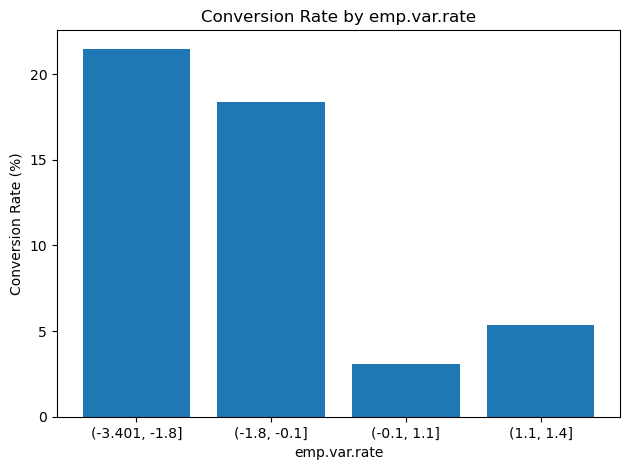

/tmp/ipykernel_137/2151832855.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp.groupby(col + '_bin')


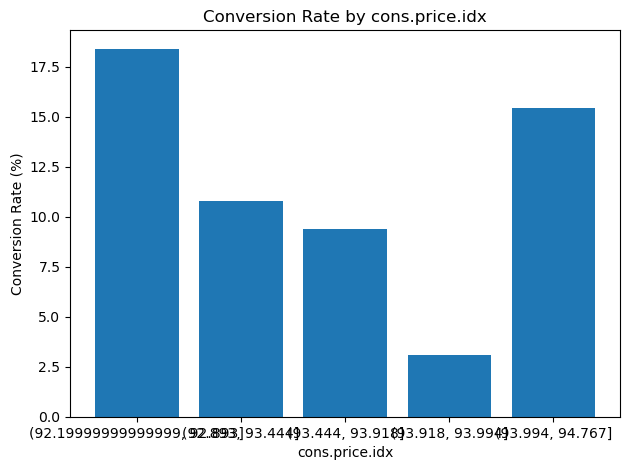

/tmp/ipykernel_137/2151832855.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp.groupby(col + '_bin')


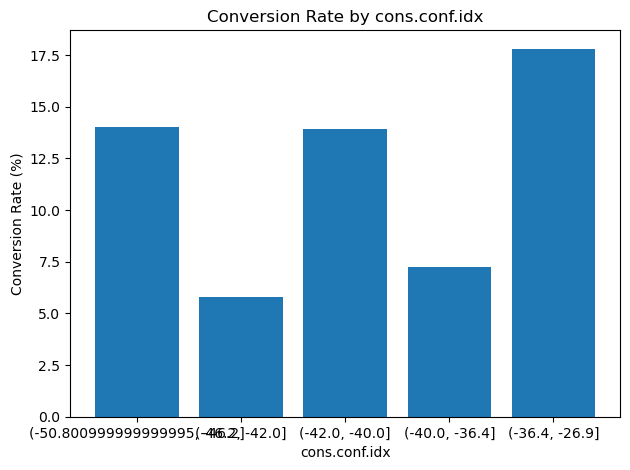

/tmp/ipykernel_137/2151832855.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp.groupby(col + '_bin')


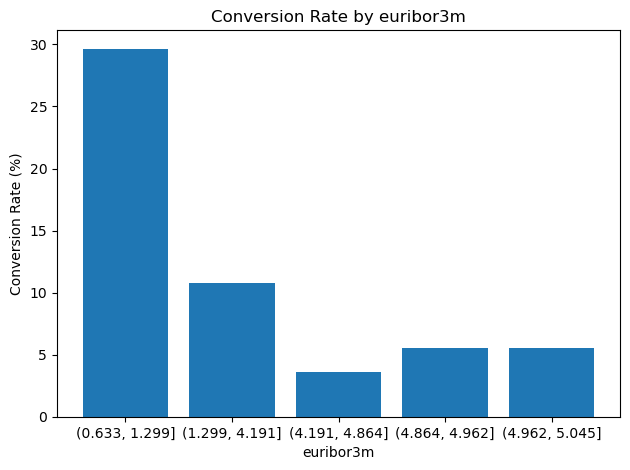

/tmp/ipykernel_137/2151832855.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp.groupby(col + '_bin')


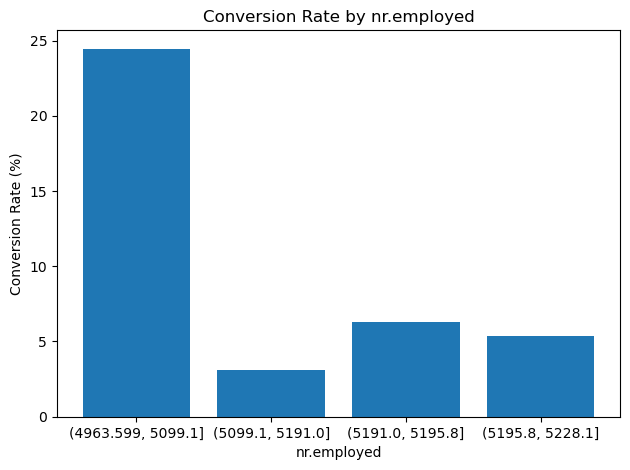

In [357]:
macro_vars = [
    'emp.var.rate',
    'cons.price.idx',
    'cons.conf.idx',
    'euribor3m',
    'nr.employed'
]
for var in macro_vars:
    result = macro_conversion_analysis(df, var)
    
    plt.figure()
    plt.bar(
        result[var + '_bin'].astype(str),
        result['conversion_rate_pct']
    )

    plt.ylabel('Conversion Rate (%)')
    plt.xlabel(var)
    plt.title(f'Conversion Rate by {var}')
    plt.tight_layout()
    plt.show()

# Conclusion and Recommendation
## Conclusion

- Secara demografi usia, kita dapat melihat tingkat konversi tertinggi dipegang oleh kelompok usia 76+, diikuti oleh 66-75, dan terakhir 18-25. Sangat menarik bagaimana kelompok termuda dan tertua justru memiliki konversi tertinggi. Usia 18-25 didominasi oleh pelajar/mahasiswa, 66-75 oleh pekerja white-collar, dan 76+ oleh pekerja blue-collar.
- Secara pekerjaan, pelajar/mahasiswa memang mendominasi, tetapi kali ini tingkat konversi tertinggi justru dipegang oleh kelompok usia 46–55.
- Diduga kuat bahwa nasabah yang masih lajang (single) juga memiliki tingkat konversi yang lebih tinggi.
- Default, pinjaman, dan kepemilikan rumah tentu sangat berpengaruh, tetapi terdapat sedikit pola perilaku yang berbeda. Telah dikonfirmasi bahwa default sangat memengaruhi tingkat konversi. Namun, untuk kategori pinjaman — baik yang memiliki pinjaman (yes), tidak (no), maupun tidak diketahui (unknown) — perbedaannya tidak terlalu mencolok. Hasil analisis kami menunjukkan bahwa hal ini bisa disebabkan karena nasabah dengan pendidikan rendah cenderung memilih produk rendah risiko, atau karena status pelajar/mahasiswa yang juga memilih risiko rendah, atau karena faktor usia lanjut/pensiunan yang mengutamakan keamanan dana. Sementara itu, untuk kepemilikan rumah, mereka yang memiliki cicilan rumah dan bekerja di sektor white-collar justru menunjukkan tingkat konversi lebih tinggi.
- Selain itu, faktor eksternal seperti metode kontak, waktu kampanye, dan kondisi ekonomi makro juga sangat berpengaruh signifikan.

## Recommendation

Prioritaskan segmen yang conversion ratenya tinggi
1. Blue-Collar 76+ => 64.7%
2. White-Collar 76+ => 60%
3. Retired 76+ => 50%
4. White-Collar 66-75 => 50%
5. Student 18-25 => 31.7%

Cari gabungan dengan variabel - variabel lain 
1. student higher_educaton 18-25 => 75%